In [1]:
!pip install -q tensorflow wandb

In [2]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import time
import os
import datetime

from tensorflow.keras.layers import Dense, Dropout, Input, Flatten
from tensorflow.keras import Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import TensorBoard, EarlyStopping

from sklearn.metrics import confusion_matrix, classification_report

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Load the Fashion-MNIST dataset
from tensorflow.keras.datasets import mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print(x_train.shape)
print(x_test.shape)

(60000, 28, 28)
(10000, 28, 28)


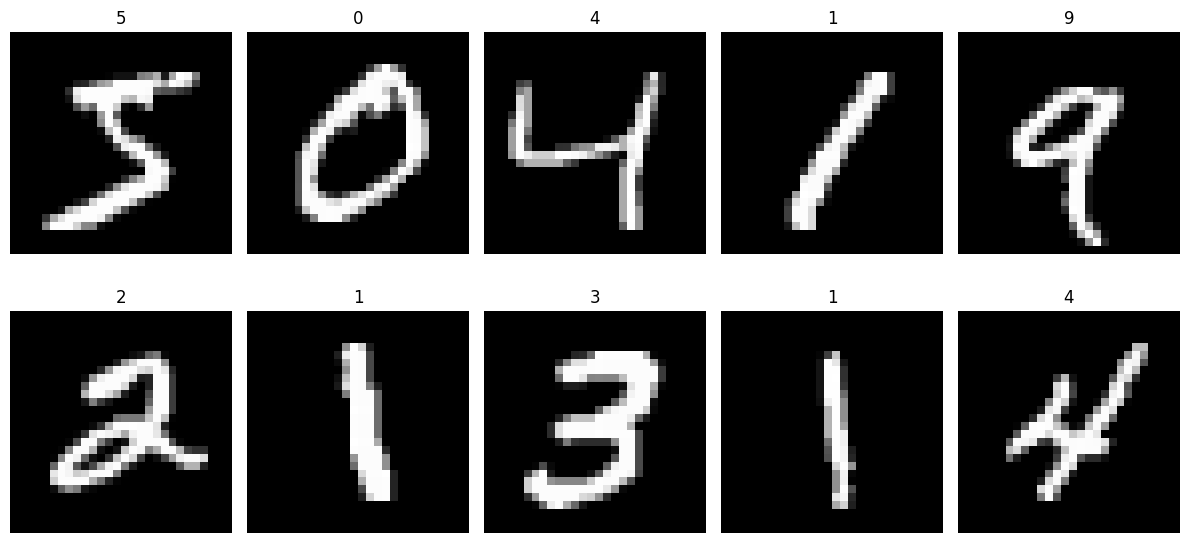

In [4]:
plt.figure(figsize=(12, 6))

for i in range(10):
  plt.subplot(2, 5, i + 1)
  plt.imshow(x_train[i], cmap="gray")
  plt.title(y_train[i])
  plt.axis("off")

plt.tight_layout()
plt.show()

In [5]:
# Data preprocessing

x_test = x_test.astype("float32") / 255.0
x_train = x_train.astype("float32") / 255.0

print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [6]:
# Configure experiment tracking
import wandb
from wandb.integration.keras import WandbMetricsLogger
wandb.login(key="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")

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: skbelekar370123 (skbelekar370123-kk-wagh-institute) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

In [7]:
experiments = [
    {
        "name" : "Experiment 1",
        "learning_rate" : 0.001,
        "batch_size" : 32,
        "layers" : [128],
    },
    {
        "name" : "Experiment 1",
        "learning_rate" : 0.01,
        "batch_size" : 32,
        "layers" : [128],
    },
    {
        "name" : "Experiment 3",
        "learning_rate" : 0.001,
        "batch_size" : 64,
        "layers" : [128],
    },
    {
        "name": "Experiment_4",
        "learning_rate": 0.001,
        "batch_size": 128,
        "layers": [256, 128, 64]
    },
    {
        "name": "Experiment_5",
        "learning_rate": 0.0001,
        "batch_size": 64,
        "layers": [128, 64]
    }
]

for exp in experiments:
    print(exp)

{'name': 'Experiment 1', 'learning_rate': 0.001, 'batch_size': 32, 'layers': [128]}
{'name': 'Experiment 1', 'learning_rate': 0.01, 'batch_size': 32, 'layers': [128]}
{'name': 'Experiment 3', 'learning_rate': 0.001, 'batch_size': 64, 'layers': [128]}
{'name': 'Experiment_4', 'learning_rate': 0.001, 'batch_size': 128, 'layers': [256, 128, 64]}
{'name': 'Experiment_5', 'learning_rate': 0.0001, 'batch_size': 64, 'layers': [128, 64]}


In [8]:
# Create a model-building function

def build_model(learning_rate, layers):
  model = Sequential()
  model.add(Flatten(input_shape=(28, 28)))

  for neurons in layers:
    model.add(Dense(neurons, activation="relu"))

  model.add(Dense(10, activation="softmax"))

  optimizer = Adam(
      learning_rate=learning_rate
  )

  model.compile(
      optimizer=optimizer,
      metrics=["accuracy"],
      loss="sparse_categorical_crossentropy"
  )

  return model

In [9]:
results = []
histories = {}
trained_models = {}

EPOCHS = 8

os.makedirs("logs", exist_ok=True)

for exp in experiments:

    print("\n" + "=" * 60)
    print("Running:", exp["name"])
    print("=" * 60)

    model = build_model(
        learning_rate=exp["learning_rate"],
        layers=exp["layers"]
    )

    log_dir = os.path.join(
        "logs",
        exp["name"] + "_" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
    )

    tensorboard_callback = TensorBoard(
        log_dir=log_dir,
        histogram_freq=0
    )

    wandb.init(
        project="mnist classification",
        name=exp["name"],
        config={
            "learning_rate": exp["learning_rate"],
            "batch_size": exp["batch_size"],
            "layers": exp["layers"],
            "epochs": EPOCHS,
            "optimizer": "Adam",
            "dataset": "Fashion-MNIST"
        },
        reinit=True
    )

    start_time = time.time()

    history = model.fit(
        x_train,
        y_train,
        epochs=EPOCHS,
        batch_size=exp["batch_size"],
        validation_split=0.1,
        callbacks=[
            tensorboard_callback,
            WandbMetricsLogger(log_freq="epoch")
        ],
        verbose=1
    )

    training_time = time.time() - start_time

    test_loss, test_accuracy = model.evaluate(
        x_test,
        y_test,
        verbose=0
    )

    wandb.log({
        "test_accuracy": test_accuracy,
        "test_loss": test_loss,
        "training_time": training_time
    })

    wandb.finish()

    histories[exp["name"]] = history.history
    trained_models[exp["name"]] = model

    results.append({
        "Experiment": exp["name"],
        "Learning Rate": exp["learning_rate"],
        "Batch Size": exp["batch_size"],
        "Hidden Layers": len(exp["layers"]),
        "Layer Configuration": str(exp["layers"]),
        "Training Accuracy": history.history["accuracy"][-1],
        "Validation Accuracy": history.history["val_accuracy"][-1],
        "Test Accuracy": test_accuracy,
        "Test Loss": test_loss,
        "Training Time (seconds)": training_time
    })

    print("\nTest Accuracy:", round(test_accuracy * 100, 2), "%")
    print("Training Time:", round(training_time, 2), "seconds")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)



Running: Experiment 1


wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


Epoch 1/8
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 14s 6ms/step - accuracy: 0.9226 - loss: 0.2730 - val_accuracy: 0.9653 - val_loss: 0.1295
Epoch 2/8
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9646 - loss: 0.1203 - val_accuracy: 0.9717 - val_loss: 0.0997
Epoch 3/8
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9749 - loss: 0.0820 - val_accuracy: 0.9783 - val_loss: 0.0829
Epoch 4/8
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9811 - loss: 0.0614 - val_accuracy: 0.9762 - val_loss: 0.0901
Epoch 5/8
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9858 - loss: 0.0468 - val_accuracy: 0.9783 - val_loss: 0.0765
Epoch 6/8
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9887 - loss: 0.0366 - val_accuracy: 0.9785 - val_loss: 0.0775
Epoch 7/8
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9910 - loss: 0.0303 - val_accuracy: 0.9817 - val_loss: 0.0722
Epoch 8/8
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9927 - loss: 0.0236 - val_ac

epoch/accuracy,▁▅▆▇▇███
epoch/epoch,▁▂▃▄▅▆▇█
epoch/learning_rate,▁▁▁▁▁▁▁▁
epoch/loss,█▄▃▂▂▁▁▁
epoch/val_accuracy,▁▄▆▆▆▆██
epoch/val_loss,█▅▃▃▂▂▁▁
test_accuracy,▁
test_loss,▁
training_time,▁
epoch/accuracy,0.99274
epoch/epoch,7



Test Accuracy: 97.58 %
Training Time: 77.06 seconds

Running: Experiment 1


... (12 outputs left out)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - accuracy: 0.8062 - loss: 0.7630 - val_accuracy: 0.9260 - val_loss: 0.2884
Epoch 2/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9164 - loss: 0.2998 - val_accuracy: 0.9417 - val_loss: 0.2125
Epoch 3/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9322 - loss: 0.2407 - val_accuracy: 0.9513 - val_loss: 0.1811
Epoch 4/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9417 - loss: 0.2069 - val_accuracy: 0.9567 - val_loss: 0.1600
Epoch 5/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9485 - loss: 0.1821 - val_accuracy: 0.9608 - val_loss: 0.1431
Epoch 6/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9539 - loss: 0.1630 - val_accuracy: 0.9633 - val_loss: 0.1339
Epoch 7/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9585 - loss: 0.1469 - val_accuracy: 0.9663 - val_loss: 0.1244
Epoch 8/8
844/844 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9619 - loss: 0.1337 - val_accuracy: 0.9665 - v

epoch/accuracy,▁▆▇▇▇███
epoch/epoch,▁▂▃▄▅▆▇█
epoch/learning_rate,▁▁▁▁▁▁▁▁
epoch/loss,█▃▂▂▂▁▁▁
epoch/val_accuracy,▁▄▅▆▇▇██
epoch/val_loss,█▅▄▃▂▂▁▁
test_accuracy,▁
test_loss,▁
training_time,▁
epoch/accuracy,0.96193
epoch/epoch,7



Test Accuracy: 96.12 %
Training Time: 37.24 seconds


In [11]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Test Accuracy",
    ascending=False
).reset_index(drop=True)

print("HYPERPARAMETER TUNING RESULTS")

display(results_df.round(4))

HYPERPARAMETER TUNING RESULTS


,Experiment,Learning Rate,Batch Size,Hidden Layers,Layer Configuration,Training Accuracy,Validation Accuracy,Test Accuracy,Test Loss,Training Time (seconds)
0,Experiment_4,0.0010,128,3,"[256, 128, 64]",0.9918,0.9797,0.9784,0.0864,25.1232
1,Experiment 3,0.0010,64,1,[128],0.9907,0.9773,0.9766,0.0744,39.8071
2,Experiment 1,0.0010,32,1,[128],0.9927,0.9822,0.9758,0.0811,77.0615
3,Experiment_5,0.0001,64,2,"[128, 64]",0.9619,0.9665,0.9612,0.1368,37.2386
4,Experiment 1,0.0100,32,1,[128],0.9737,0.9655,0.9608,0.2160,67.5152


In [12]:
display(results_df.round(4))

,Experiment,Learning Rate,Batch Size,Hidden Layers,Layer Configuration,Training Accuracy,Validation Accuracy,Test Accuracy,Test Loss,Training Time (seconds)
0,Experiment_4,0.0010,128,3,"[256, 128, 64]",0.9918,0.9797,0.9784,0.0864,25.1232
1,Experiment 3,0.0010,64,1,[128],0.9907,0.9773,0.9766,0.0744,39.8071
2,Experiment 1,0.0010,32,1,[128],0.9927,0.9822,0.9758,0.0811,77.0615
3,Experiment_5,0.0001,64,2,"[128, 64]",0.9619,0.9665,0.9612,0.1368,37.2386
4,Experiment 1,0.0100,32,1,[128],0.9737,0.9655,0.9608,0.2160,67.5152


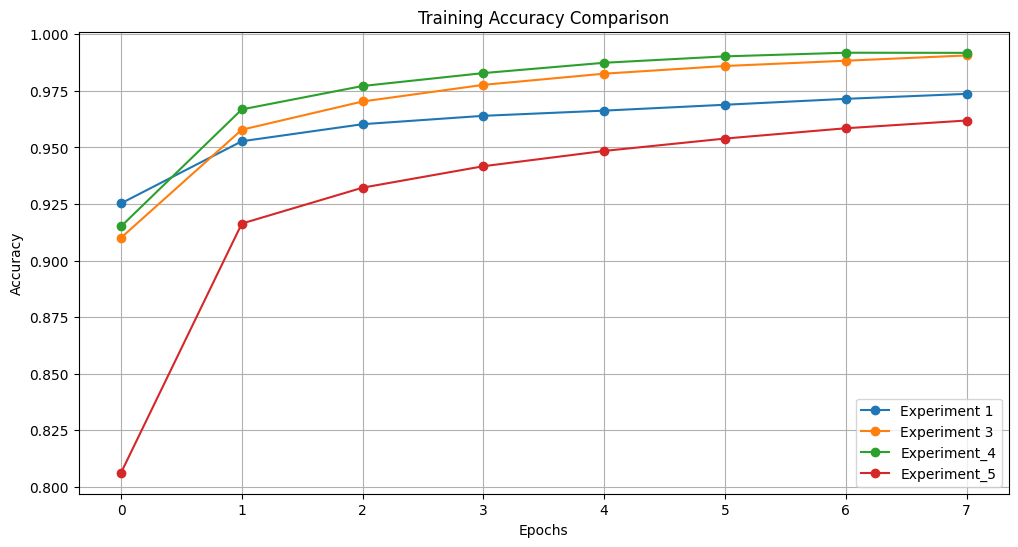

In [13]:
plt.figure(figsize=(12, 6))

for name, history in histories.items():
    plt.plot(
        history['accuracy'],
        marker='o',
        label=name
    )

plt.title("Training Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

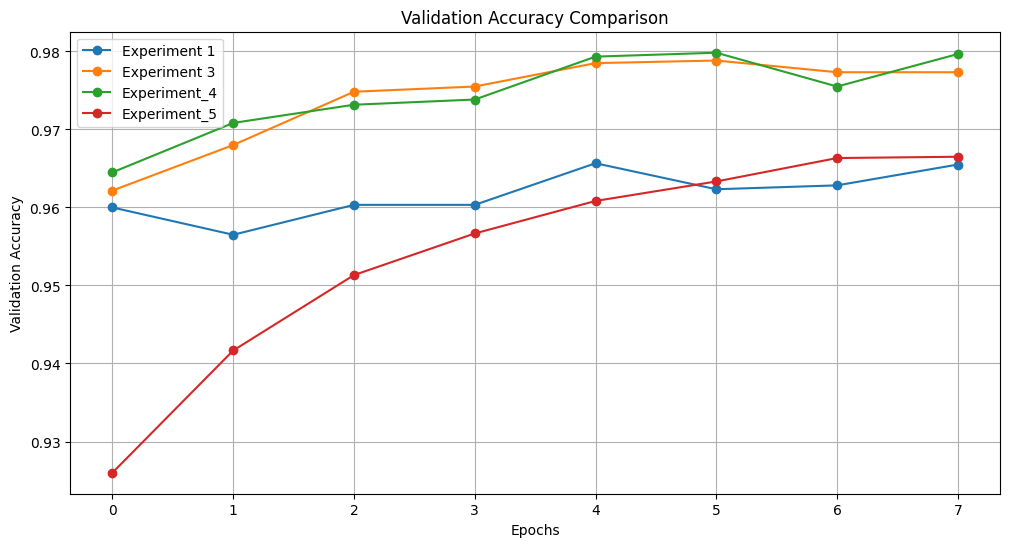

In [14]:
plt.figure(figsize=(12, 6))

for name, history in histories.items():
    plt.plot(
        history['val_accuracy'],
        marker='o',
        label=name
    )

plt.title("Validation Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

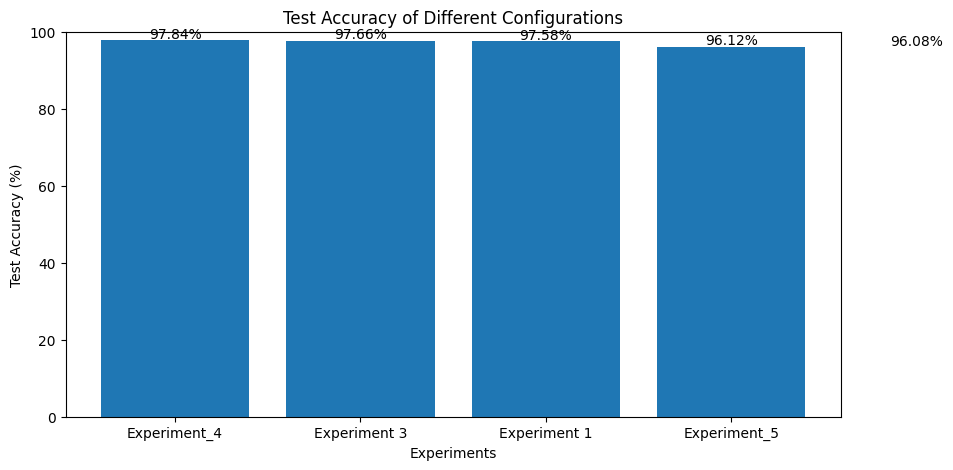

In [15]:
plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Experiment"],
    results_df["Test Accuracy"] * 100
)

plt.title("Test Accuracy of Different Configurations")
plt.xlabel("Experiments")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 100)

for i, value in enumerate(results_df["Test Accuracy"] * 100):
    plt.text(i, value + 0.5, f"{value:.2f}%", ha='center')

plt.show()